# Pós-Graduação em IA Aplicada
### Unidade Curricular: Machine Learning
**Professor:** Giancarlo Marchesini, Me.

**Aluno:** Adair José Limana.

---

# Estudo Dirigido: Detecção de Anomalias e Previsão de Séries Temporais

Com **uma única série real de táxis de Nova York**, a turma vai:

- **Aula 1:** aplicar os **7 detectores** da aula de anomalias (**Z-Score**, **IQR**, **Isolation Forest**, **One-Class SVM**, **LOF**, **Elliptic Envelope** e **K-Means**) e **plotar as anomalias em vermelho**.

> ▶️ **Como usar no Google Colab:** `Arquivo > Fazer upload de notebook`, envie este `.ipynb` e execute as células **em ordem**. O Colab precisa de internet (os dados vêm do GitHub).

## Objetivos

1. **Aplicar** os 7 detectores da aula a uma série temporal e **visualizar** as anomalias.
2. **Percorrer** o ciclo completo de um modelo de previsão: dados, lags, pipeline, treino, validação, **salvamento** e uso.
3. **Justificar** a escolha dos lags pela autocorrelação e **experimentar** outras combinações.
4. **Repetir** o mesmo pipeline em um dataset diferente.

## O dataset: NYC Taxi (Numenta Anomaly Benchmark)

| Característica | Valor |
|---|---|
| Amostras | 10.320 leituras, uma a cada 30 min (01/07/2014 a 31/01/2015) |
| Variáveis | 1 (`value`: passageiros de táxi em Nova York no intervalo) |
| Classes | 5 **janelas** de anomalia: maratona de NY, Ação de Graças, Natal, Ano Novo e tempestade de neve |
| Valores faltantes | Nenhum |
| Fonte | Numenta Anomaly Benchmark (NAB), `realKnownCause/nyc_taxi.csv` |

Série de **transporte e logística**, com **ciclo diário e semanal** e eventos reais rotulados.

In [1]:
# Setup: bibliotecas da aula inteira e semente fixa
import json
import urllib.request
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.ensemble import IsolationForest, RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import OneClassSVM, SVR
from sklearn.neighbors import LocalOutlierFactor
from sklearn.covariance import EllipticEnvelope
from sklearn.cluster import KMeans
from sklearn.linear_model import Ridge

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from statsmodels.graphics.tsaplots import plot_acf

warnings.filterwarnings("ignore")
SEMENTE = 42
np.random.seed(SEMENTE)
plt.rcParams.update({"figure.figsize": (14, 3.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
print("Setup concluído.")

Setup concluído.


# Módulo 1 — Os dados

> 🎯 **Objetivo:** carregar a série e separar treino e teste em ordem cronológica.

O **treino** (01/07 a 29/10/2014) tem só dados **normais**. O **teste** (30/10/2014 a 31/01/2015) tem as 5 janelas de anomalia (faixas vermelhas claras). Como na aula, nenhum detector usa rótulos.

> ▶️ **Esta célula já vem pronta.**

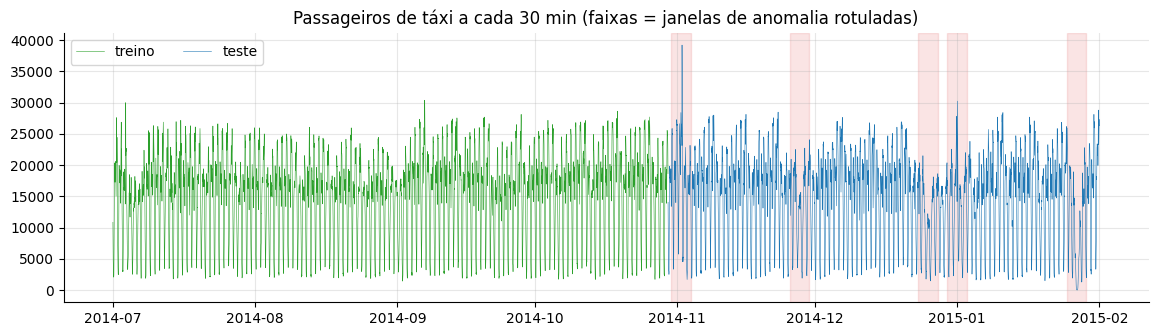

In [2]:
URL_DADOS = "https://raw.githubusercontent.com/numenta/NAB/master/data/realKnownCause/nyc_taxi.csv"
URL_ROTULOS = "https://raw.githubusercontent.com/numenta/NAB/master/labels/combined_windows.json"

serie = pd.read_csv(URL_DADOS, parse_dates=["timestamp"], index_col="timestamp")["value"].astype(float).asfreq("30min")
with urllib.request.urlopen(URL_ROTULOS) as resposta:
    janelas = [(pd.Timestamp(i), pd.Timestamp(f)) for i, f in json.load(resposta)["realKnownCause/nyc_taxi.csv"]]

FIM_TREINO = pd.Timestamp("2014-10-29 23:30")
m_treino = serie.index <= FIM_TREINO
m_teste = ~m_treino

def sombrear_janelas(ax):
    for ini, fim in janelas:
        ax.axvspan(ini, fim, color="tab:red", alpha=0.12)

fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(serie[m_treino], lw=0.4, color="tab:green", label="treino")
ax.plot(serie[m_teste], lw=0.4, color="tab:blue", label="teste")
sombrear_janelas(ax)
ax.set_title("Passageiros de táxi a cada 30 min (faixas = janelas de anomalia rotuladas)")
ax.legend(loc="upper left", ncol=2)
plt.show()

> 📌 **Leitura:** há um **ciclo diário** (vale de madrugada, pico no fim do dia) e um **ciclo semanal**. Esse ritmo é o **normal**.

# Módulo 2 — Aplicando os 7 detectores

> 🎯 **Objetivo:** aplicar os 7 detectores e **plotar as anomalias em vermelho**.

Cada detector gera um **score** (maior = mais suspeito). O **limiar** é o percentil 99,5 dos scores **no treino** (o papel do `contamination` da aula): só 0,5% do período normal viraria alarme.

**Z-Score.** Distância à média em desvios-padrão: $z = |x - \mu| / \sigma$ (com $\mu$, $\sigma$ do treino).
**IQR.** Distância à mediana em unidades de $\text{IQR} = Q_3 - Q_1$ (com $Q_1$, $Q_3$ do treino).
**Isolation Forest.** Anomalias são fáceis de **isolar** com cortes aleatórios.
**One-Class SVM.** Uma **fronteira** em volta do normal.
**LOF.** Suspeito é o ponto numa região **menos densa que a de seus vizinhos** (`novelty=True`, como na aula).
**Elliptic Envelope.** Uma **elipse** (gaussiana robusta) em volta do normal.
**K-Means.** Score = distância ao centróide mais próximo (`k=4`, como na aula).

Os cinco últimos recebem 6 atributos: `valor`, `hora` e `dia da semana` (em seno e cosseno) e **`variacao_semana`**, o **contexto**: quanto o valor mudou em relação ao **mesmo horário da semana passada**. Valor baixo às 4h é normal; o mesmo valor às 19h de uma quinta, não.

> ▶️ **Esta célula já vem pronta.**

In [3]:
hora = serie.index.hour + serie.index.minute / 60
dia_semana = serie.index.dayofweek
variacao_semana = serie / serie.shift(336) - 1        # 336 pontos de 30 min = 7 dias

X = pd.DataFrame({
    "valor": serie.values,
    "hora_sin": np.sin(2 * np.pi * hora / 24), "hora_cos": np.cos(2 * np.pi * hora / 24),
    "dia_sin": np.sin(2 * np.pi * dia_semana / 7), "dia_cos": np.cos(2 * np.pi * dia_semana / 7),
    "variacao_semana": variacao_semana.fillna(0).values,
}, index=serie.index)

mascara_ajuste = m_treino & variacao_semana.notna().values   # treino, sem a primeira semana
PERCENTIL_LIMIAR = 99.5
print("Atributos:", list(X.columns))

Atributos: ['valor', 'hora_sin', 'hora_cos', 'dia_sin', 'dia_cos', 'variacao_semana']


SUA VEZ — DESAFIO FINAL: DETECÇÃO DE ANOMALIAS

Agora é a sua vez de implementar a solução de detecção de anomalias.

Siga as etapas abaixo:

1 - MÉTODOS ESTATÍSTICOS

Calcule dois scores de anomalia utilizando apenas os dados de treino:
- Z-Score: distância do valor em relação à média, normalizada pelo desvio-padrão.
- IQR: distância do valor em relação à mediana, normalizada pelo intervalo interquartil (Q3 − Q1).

2 - MÉTODOS DE MACHINE LEARNING

Implemente e compare os seguintes métodos:
- Isolation Forest
- One-Class SVM
- Local Outlier Factor
- Elliptic Envelope
- K-Means

Para os métodos de Machine Learning, utilize padronização dos dados antes da detecção e ajuste cada modelo exclusivamente utilizando os dados de treino destinados ao ajuste.

3 - SCORE DE ANOMALIA

Para cada método, obtenha um score em que valores maiores representem maior probabilidade de o ponto ser uma anomalia.

No caso do K-Means, utilize a distância do ponto em relação ao centróide ao qual ele foi associado como medida de anomalia.

4 - DEFINIÇÃO DO LIMIAR

Defina um limiar de anomalia para cada método utilizando um percentil dos scores calculados no conjunto de treino.

Considere como anomalias, no conjunto de teste, os pontos cujo score esteja acima do limiar definido.

5 - VISUALIZAÇÃO

Para cada método, gere um gráfico contendo:
- a série do conjunto de teste em cinza;
- os pontos identificados como anomalias destacados em vermelho.

6 - COMPARAÇÃO DOS RESULTADOS

Compare os resultados obtidos pelos diferentes métodos.

Identifique:
- quais pontos foram classificados como anomalias;
- quais métodos apresentaram resultados semelhantes;
- quais anomalias foram identificadas de forma consistente por diferentes métodos;
- quais métodos apresentaram comportamentos significativamente diferentes.

IMPORTANTE:
O objetivo principal deste desafio é a implementação da etapa de DETECÇÃO DE ANOMALIAS. A análise e comparação dos resultados também fazem parte da avaliação.

In [4]:
def plotar_anomalias(x, y, flag, titulo):
    """Espalha os pontos e destaca em vermelho os marcados como anomalia."""
    plt.figure(figsize=(8, 4.5))
    plt.scatter(x[flag == 0], y[flag == 0], s=10, alpha=0.4, color="gray", label="Normal")
    plt.scatter(x[flag == 1], y[flag == 1], s=18, color="crimson", label="Anomalia")
    plt.xlabel("Índice")
    plt.ylabel("Número de passageiros de táxi")
    plt.title(titulo)
    plt.legend()
    plt.tight_layout()
    plt.show()

TAXA_CONTAMINACAO=0.01 #Assumindo uma taxa de 1% de anomalias

X_treino = X[m_treino]
X_teste = X[m_teste]
indice_teste = X_teste.index

##1 Métodos estatistícos

###1.1 Z-Score

In [5]:
LIMIAR_Z_SCORE = 2
media_treino = X_treino["valor"].mean()
desvio_treino = X_treino["valor"].std()

if desvio_treino == 0:
    raise ValueError("O desvio-padrão do treino é zero")

z_treino = ((X_treino["valor"] - media_treino) / desvio_treino).abs() > LIMIAR_Z_SCORE

z_teste = ((X_teste["valor"] - media_treino) / desvio_treino).abs() > LIMIAR_Z_SCORE

scores_treino = {"Z-Score": z_treino}
scores_teste = {"Z-Score": z_teste}

###1.2 IQR

In [6]:
q1 = X_treino["valor"].quantile(0.25)
mediana = X_treino["valor"].median()
q3 = X_treino["valor"].quantile(0.75)

iqr = q3 - q1

if iqr == 0:
  raise ValueError("O IQR do treino é zero")

iqr_treino = (X_treino["valor"] - mediana).abs() / iqr

iqr_teste = (X_teste["valor"] - mediana).abs() / iqr

scores_treino["IQR"] = iqr_treino
scores_teste["IQR"] = iqr_teste

##2 Métodos de ML

###2.1 Isolation Forest

In [7]:
pipeline_isolation_forest = Pipeline([
    ("escalonador", StandardScaler()),
    ("detector", IsolationForest(contamination=TAXA_CONTAMINACAO, random_state=SEMENTE)),
])
pipeline_isolation_forest.fit(X_treino)

scores_treino["Isolation Forest"] = -pipeline_isolation_forest.decision_function(
    X_treino
)

scores_teste["Isolation Forest"] = -pipeline_isolation_forest.decision_function(
    X_teste
)

###2.2 One Class SVM

In [8]:
pipeline_one_class_svm = Pipeline([
    ("escalonador", StandardScaler()),
    ("detector", OneClassSVM(kernel="rbf", gamma="scale", nu=TAXA_CONTAMINACAO))
])

pipeline_one_class_svm.fit(X_treino)

scores_treino["One-Class SVM"] = -pipeline_one_class_svm.decision_function(
    X_treino
)

scores_teste["One-Class SVM"] = -pipeline_one_class_svm.decision_function(
    X_teste
)

###2.3 Local Outlier Factor

In [9]:
pipeline_lof = Pipeline([
    ("escalonador", StandardScaler()),
    ("detector", LocalOutlierFactor(n_neighbors=20, contamination=TAXA_CONTAMINACAO, novelty=True)),
])
pipeline_lof.fit(X_treino)

scores_treino["Local Outlier Factor"] = (
    -pipeline_lof.decision_function(X_treino)
)

scores_teste["Local Outlier Factor"] = (
    -pipeline_lof.decision_function(X_teste)
)

###2.4 Elliptic Envelope

In [10]:
pipeline_elliptic_envelope = Pipeline([
    ("escalonador", StandardScaler()),
    ("detector",  EllipticEnvelope(contamination=TAXA_CONTAMINACAO, random_state=SEMENTE)),
])

pipeline_elliptic_envelope.fit(X_treino)

scores_treino["Elliptic Envelope"] = (
    -pipeline_elliptic_envelope.decision_function(X_treino)
)

scores_teste["Elliptic Envelope"] = (
    -pipeline_elliptic_envelope.decision_function(X_teste)
)

###2.5 K-Means

In [11]:
pipeline_k_means = Pipeline([
    ("escalonador", StandardScaler()),
    ("detector", KMeans(n_clusters=2, n_init=10, random_state=SEMENTE)),
])

pipeline_k_means.fit(X_treino)

distancias_treino = pipeline_k_means.named_steps["detector"].transform(
    pipeline_k_means.named_steps["escalonador"].transform(X_treino)
).min(axis=1)

distancias_teste = pipeline_k_means.named_steps["detector"].transform(
    pipeline_k_means.named_steps["escalonador"].transform(X_teste)
).min(axis=1)

scores_treino["K-Means"] = distancias_treino
scores_teste["K-Means"] = distancias_teste

##3 Definição do limiar por métodos

In [12]:
scores_treino = {
    nome: pd.Series(
        np.asarray(score).ravel(),
        index=X_treino.index,
        dtype=float
    )
    for nome, score in scores_treino.items()
}

scores_teste = {
    nome: pd.Series(
        np.asarray(score).ravel(),
        index=X_teste.index,
        dtype=float
    )
    for nome, score in scores_teste.items()
}

limiares = {
    nome: score.quantile(PERCENTIL_LIMIAR / 100)
    for nome, score in scores_treino.items()
}

flags_teste = pd.DataFrame(index=X_teste.index)

for nome, score in scores_teste.items():
    flags_teste[nome] = (
        score > limiares[nome]
    ).astype(int)

flags_treino = pd.DataFrame(index=X_treino.index)

for nome, score in scores_treino.items():
    flags_treino[nome] = (
        score > limiares[nome]
    ).astype(int)

resumo = pd.DataFrame({
    "Limiar": pd.Series(limiares),
    "Anomalias no teste": flags_teste.sum(),
})

print(resumo.to_string())

                         Limiar  Anomalias no teste
Z-Score                0.000000                  46
IQR                    1.699186                  77
Isolation Forest       0.015364                  98
One-Class SVM          0.014207                 710
Local Outlier Factor   0.030212                 518
Elliptic Envelope     78.490429                 109
K-Means                4.835348                 145


##4 Gráficos

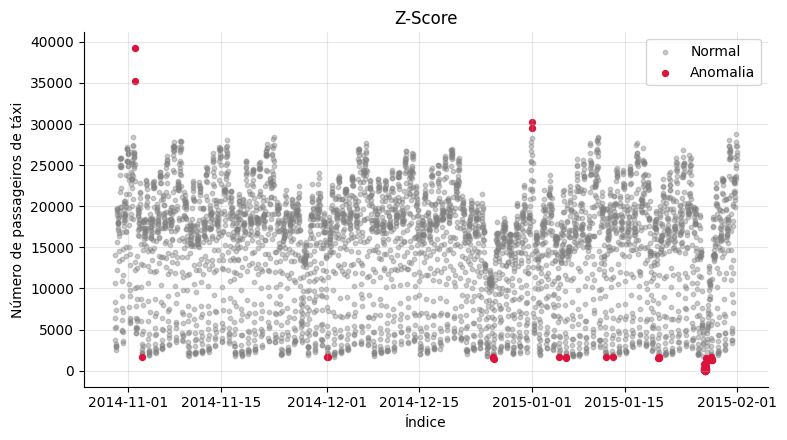

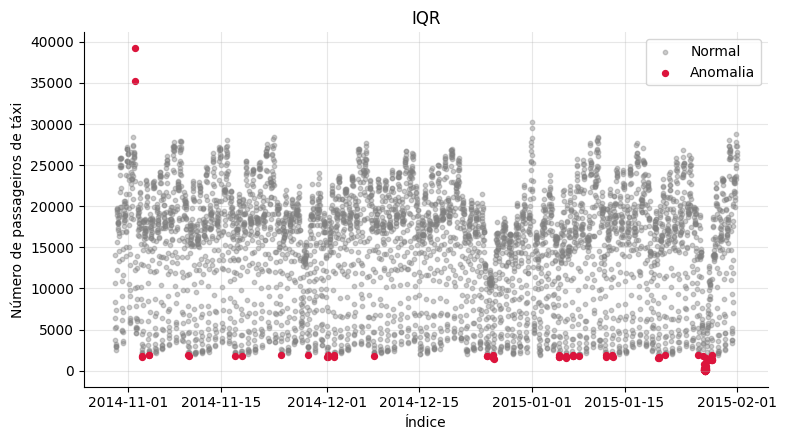

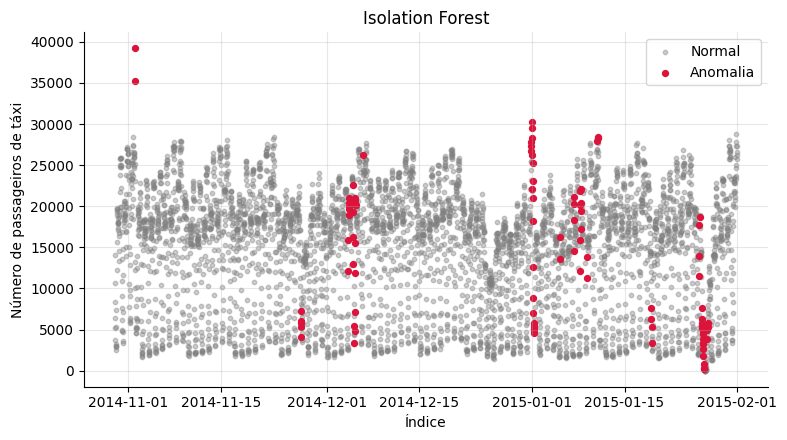

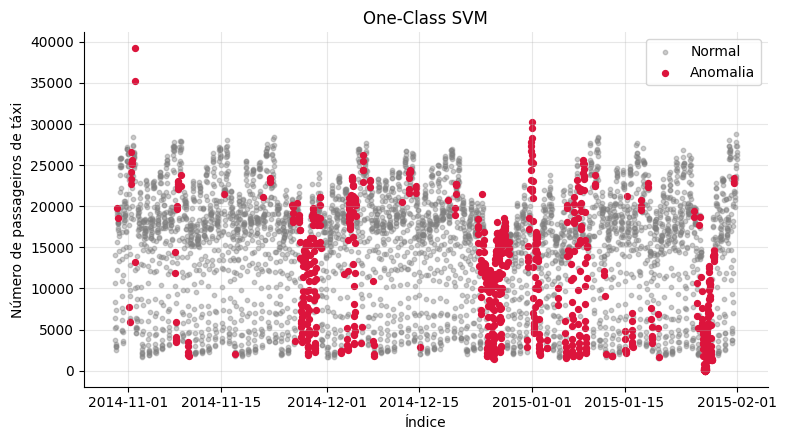

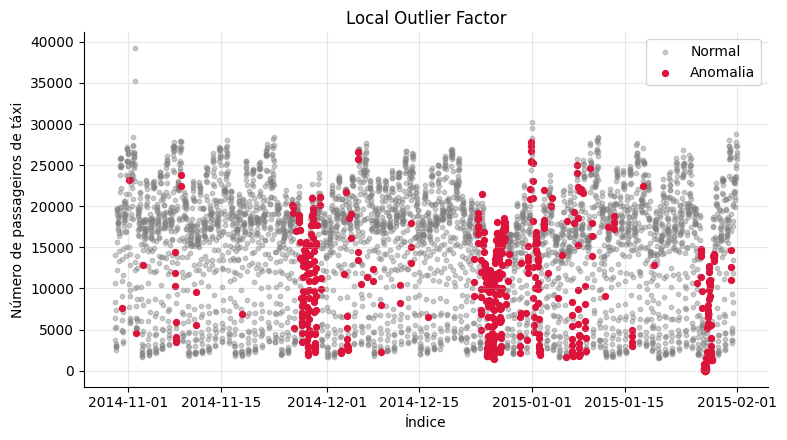

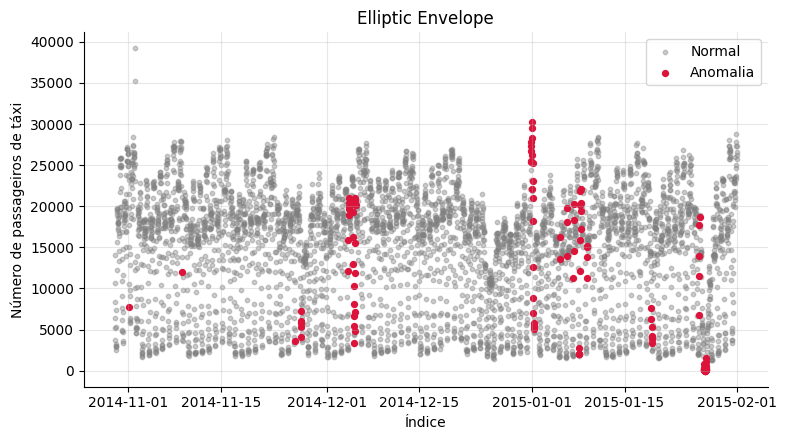

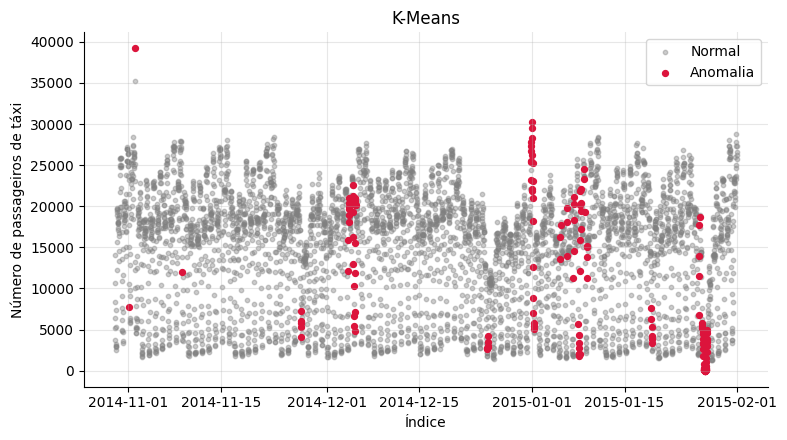

In [13]:
for nome in flags_teste.columns:
    plotar_anomalias(
        X_teste.index,
        X_teste["valor"].values,
        flags_teste[nome].values,
        nome
    )

    print()

##5 Análise

Quais pontos foram classificados como anomalias?

**Z-Score**: Destaca os dois valores extremamente altos do início de novembro e outro pico próximo de 30 mil passageiros no início de janeiro. Também identifica pontos muito baixos em diferentes datas, principalmente observações próximas de zero a 2 mil passageiros.

**IQR**: Identifica dois valores extremamente altos, acima de 35 mil passageiros, no início de novembro. Também classifica diversas obsevações muito baixas, próximas de zero a 2 mil passageiros, ao longo de todo o período, com concentração visível no fim de janeiro.

**Isolation Forest**: Identifica os extremos do início de novembro, grupos de observações no início de dezembro e várias concentrações em janeiro. Os pontos destacados incluem tanto valores baixos, próximos de 4 mil a 8 mil passageiros, quanto valores intermediários e altos, chegando a aproximadamente 30 mil.

Diferente dos métodos estatísticos,n ão se limita a identificar valores nas extremidades da distribuição.

**K-Means**: Destaca um valor próximo de 39 mil passageiros, observações em grupos do início de dezembro e de janeiro e diversos pontos baixos, especialmente no fim de janeiro. Também marca observações de valores intermediários, próximos de 10 mil a 25 mil passageiros.

**Elliptic Envelope**: Apresenta um padrão semelhante ao Isolation Fores e ao K-Means, com concentrações de anomalias n início de dezembro, no início e no decorrer de janeiro e no final do mês.

**Local Outlier Factor**: Identifica concentrações de pontos classificados como anômalos, especialmente no final de novembro e início de dezembro, na transição de dezembro para janeiro, na primeira metade de janeiro e no fim do mês.

Destaca observações de diversas magnitudes, inclusive valores intermediários e elevados. Isso é compatível com seu critério de densidade local, um ponto pode ser anômalo por estar em uma região de densidade diferente daquela de seus vizinhos.

**One-Class SVM**: É visualmente um dos métodos que mais distribuem classificações de anomalia ao longo da série. Além de valores extremos, destaca grupos densos de observações no início de dezembrom no final de dezembro e início de janeiro, na primeira metade de janeiro e no final do período.

\
Quais métodos apresentaram resultados semelhantes?

**Z-Score e IQR**: Concentram nos valores extremos, principalmente nas observações muito baixas e nos picos superiores.

**Isolation Forest, Elliptic Envelope e K-Means**: Apresentam diversas concentrações de anomalias em períodos semelhantes, especialmente em dezembro, janeiro e fevereiro.

**One-Class SVM e Local Outlier Factor**: Identificam grupos densos de anomalias e sinalizam uma quantidade visualmente maior de observações em determinados intervalos.

\
Quais anomalias foram identificadas de forma consistente por diferentes métodos?

**Picos do início de novembro**: Os valores próximos de 35 mil e 39 mil são identificados pelo IQR e pelo Z-Score. O Isolation Forest e o One-Class SVM também destacam esses extremos, e o K-Means senaliza pelo menos um deles.

**Concentrações no início de dezembro e na transição para janeiro**: Isolation Forest, K-Means, Elliptic Envelope, Local Outlier Factor e One-Class SVM apresentam pontos classificaods como anomalias em períodos próximos. Entreando, não necessariamente são os mesmos timestamps. Os métodos também selecionam observações com valores diferentes dentro desses grupos.

**Valores próximos de zero no fim de janeiro**: Há valores extremamente baixos destacados por todos os métodos.


\
Quais métodos apresentaram comportamentos significativamente diferentes?

**IQR e Z-Score vs métodos de Machine Learning**: A principal diferença é que os métodos estatísticos dependem diretamente da distância em relação a medidas globais da distribuição. Isso favorece a identificação de valores extremos.

Os métodos de ML, por sua vez, identificam anomalias conforme critérios específico de isolamento, densidade, região estatístiva ou distância aos centróides. Por isso, podem detectar observações intermediárias que os métodos estatísticos não classificam com anômalas.


**Local Outlier Factor e One-Class SVM vs Isolation Forest, Elliptic Envelope e K-Means**: É possível observar uma diferença significativa nos resultados obtidos pelos métodos Local Outlier Factor e One-Class SVM em comparação com Isolation Forest, Elliptic Envelope e K-Means. Visualmente, o Local Outlier Factor e One-Class SVM identificaram uma quantidade maior de observações como anômalas em determinados intervalos, formando concentrações de pontos classificados como anomalias, especialmente no final de novembro, no início de dezembro, na transição de dezembro para janeiro e em diferentes períodos de janeiro. Em contrapartidam o Isolation Forest, Elliptic Envelope e K-Means apresentaram detecções relatimanete masi dispersas e concentradas em grupos específicos de observações, identificando menos pontos em algumas dessas.  


##6 Referência
- Lavin, A.; Ahmad, S. **Evaluating Real-time Anomaly Detection Algorithms: the Numenta Anomaly Benchmark.** IEEE ICMLA, 2015. Dados: `numenta/NAB`, originados da NYC Taxi & Limousine Commission.